# Serie II · Fábrica — 09. Anomalías, alertas tempranas y eficiencia

**Pregunta 4:** aplicar al menos un método no supervisado de detección de anomalías, proponer reglas de alerta temprana
para el jefe de calderas y explicar cómo se distingue una falla del equipo de una falla del sensor.

**Pregunta 5:** identificar al menos dos oportunidades de mejora en la combustión o la operación, estimar su impacto
con supuestos documentados y decir qué datos faltan para estimarlo con confianza.

**La idea central para separar sensor de equipo.**
- **Un sensor que falla se separa de sus pares y de la física.** Su gemelo, sus vecinos y los balances siguen
  diciendo otra cosa.
- **Un equipo que falla mueve varias variables acopladas a la vez, y los sensores redundantes coinciden.** Si las seis
  presiones de hogar suben juntas, el hogar se presurizó; si sube una sola, falló esa.

Por eso hay dos detectores con propósitos distintos, más reglas físicas simples:

| Capa | Qué mira | Responde |
|---|---|---|
| Reglas del jefe de calderas | umbrales físicos con persistencia, cada 5 s | ¿hay que actuar ya? |
| Verificación de sensores | cada sensor contra sus pares redundantes o un modelo físico | ¿falló un sensor? |
| Monitor del proceso (PCA, T²) | combinación de variables de proceso contra las últimas 24 h | ¿la caldera opera fuera de lo normal? |

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from sklearn.linear_model import LinearRegression
warnings.filterwarnings("ignore", category=RuntimeWarning)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from fabrica_datos import cargar, variables_derivadas, PRESION_HOGAR
from fabrica_sensor_virtual import tabla_minuto
from fabrica_anomalias import (residuos_verificacion, ajustar_referencia, puntajes_verificacion, persistente, con_histeresis,
                               episodios, sensores_congelados, tabla_proceso, monitor_t2, reglas_jefe, inyectar)
from fabrica_eficiencia import (SupuestosCaldera, calor_util_gj_h, combustible_t_h, exceso_aire, puntos_por_chimenea,
                                puntos_por_exceso_aire, ahorro, kw_tiro)

RAW = ROOT / "data" / "raw" / "serie2"
FIG = ROOT / "outputs" / "figures"; TAB = ROOT / "outputs" / "tables"; MOD = ROOT / "outputs" / "models"
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
AZUL, NARANJA, AQUA, AMARILLO, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#9a9993"
TINTA, TINTA2, REJILLA = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": REJILLA, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": TINTA, "font.size": 10,
})
def guardar(fig, nombre):
    fig.tight_layout(); fig.savefig(FIG / nombre, bbox_inches="tight"); plt.show()

DF = cargar(RAW / "data.csv")
INICIO = DF.index[0]; FIN_REF = INICIO + pd.Timedelta("48h")
PERSISTE_MIN, APAGA_MIN, Q_MONITOR = 5, 15, 0.999
EVENTO_RETORNO = pd.Timestamp(json.loads((TAB / "serie2_resumen_p1.json").read_text(encoding="utf-8"))["salto_retorno"])
print(f"Referencia de 'normal': {INICIO:%d/%m %H:%M} → {FIN_REF:%d/%m %H:%M} (2 días); evaluación: los 3 días siguientes")

Referencia de 'normal': 27/03 14:28 → 29/03 14:28 (2 días); evaluación: los 3 días siguientes


# Parte A · Pregunta 4: anomalías y alertas

## A.1 Reglas para el jefe de calderas

Umbrales físicos con **persistencia**: una condición tiene que durar un tiempo mínimo para alertar, así un pico de 5 s
no genera alarmas. Los umbrales de temperatura se fijaron con estos mismos datos para que cada regla dispare alrededor
de una vez al día o menos: sus frecuencias salen en parte por construcción. Con los límites de diseño de la caldera real se reemplazan.

In [2]:
J = reglas_jefe(DF)
REG = pd.DataFrame({"eventos por día": {c: len(episodios(J[c])) / 5 for c in J.columns},
                    "minutos en 5 días": {c: J[c].sum() * 5 / 60 for c in J.columns}})
display(REG.round(1))
ev = episodios(J.iloc[:, 0])
vistos = [(DF.loc[r["inicio"]:r["fin"], PRESION_HOGAR] > 0).mean().mean() for _, r in ev.iterrows()]
print(f"Hogar presurizado: {len(ev)} eventos, duración mediana {ev['muestras'].median() * 5:.0f} s; "
      f"en la mediana de los eventos, el {100 * np.median(vistos):.0f} % de las lecturas de los 6 sensores está en positivo")

,eventos por día,minutos en 5 días
"Hogar presurizado (mediana > 0 Pa, 10 s)",1.8,1.7
"O₂ bajo (< 1.2 %, 2 min)",0.8,28.4
"O₂ alto (> 3 %, 10 min)",0.4,8.1
"Vapor caliente (> 548 °C, 2 min)",0.8,7.5
"Vapor frío (< 526 °C, 5 min)",1.0,7.1
"Lecho alto (> 11,300 Pa, 5 min): descargar",0.2,20.6
"Corriente del tiro alta (> 26 A, 1 min)",0.8,13.1


Hogar presurizado: 9 eventos, duración mediana 10 s; en la mediana de los eventos, el 89 % de las lecturas de los 6 sensores está en positivo


| Alerta | Qué significa | Qué hacer |
|---|---|---|
| Hogar presurizado | gases empujando hacia afuera: riesgo para el personal y las mirillas | revisar tiro inducido y alimentación; si se repite, bajar carga |
| O₂ bajo | combustión con poco aire: riesgo de CO e inquemados | subir aire secundario; revisar el analizador si el otro lado no coincide |
| O₂ alto | aire de más: calor que se va por la chimenea (pregunta 5) | bajar aire secundario; revisar compuertas y fugas |
| Vapor caliente | riesgo para el sobrecalentador y la turbina | revisar la atemperación (¿válvula en manual?) |
| Vapor frío | pérdida de eficiencia en la turbina | revisar si se está atemperando de más y el exceso de aire |
| Lecho alto | demasiado material en el fondo: más presión para el ventilador primario | descargar ceniza de fondo |
| Corriente del tiro alta | el tiro trabaja al límite | revisar ensuciamiento, fugas de aire y exceso de aire |

**Lectura.** Las presurizaciones del hogar son reales: en ellas casi todas las lecturas de los seis sensores están en
positivo a la vez, no una sola. Es el primer ejemplo del criterio sensor contra equipo.

## A.2 Verificación de sensores (redundancia y física)

Cada chequeo compara un sensor con lo que **debería** marcar según sus pares:
- Cada presión de hogar contra la mediana de las otras cinco.
- Los pares izquierda-derecha: O₂, lecho, gases y aire de retorno.
- El flujo de vapor medido contra el sensor virtual de dos variables de la pregunta 3, reajustado aquí solo con los
  2 días de referencia.
- El agua de atemperación contra la apertura de su válvula.

Cada residuo se estandariza con su mediana y su desvío robusto de la referencia (z).
- **Umbral por chequeo:** el menor de 5, 6, 7, 8 o 10 desvíos que en los 2 días de referencia no dio ninguna
  alarma. Los chequeos más ruidosos quedan con umbral más alto.
- **Persistencia:** hay alarma si |z| supera el umbral 5 min seguidos, y se apaga tras 15 min sin condición.
- **Confirmación del operador:** cuando el operador confirma un cambio deliberado (la redistribución del aire de
  retorno del 30/03), ese chequeo se pausa 2 h para recalibrarse y toma como nuevo centro la mediana de esas 2 h.
- **Varias presiones de hogar a la vez:** si saltan dos o más chequeos de presión de hogar al mismo tiempo, no son
  varios sensores dañados sino un evento del hogar (proceso).
- **Congelado:** un sensor que repite el mismo valor el doble de lo máximo que lo hizo en la referencia (y al menos
  1 min).

In [3]:
def verificar(df, ref_modelos=None):
    M = df.resample("1min").mean().interpolate(limit=3)
    TM = tabla_minuto(df)
    ref = M.index < FIN_REF
    if ref_modelos is None:
        Xv = TM.loc[ref, ["raiz_dp_rho", "YJJWSLL"]].dropna(); vir = LinearRegression().fit(Xv, TM.loc[Xv.index, "ZZQBCHLL"])
        ref_modelos = {"virtual": vir}
    vv = pd.Series(ref_modelos["virtual"].predict(TM[["raiz_dp_rho", "YJJWSLL"]].ffill()), index=TM.index)
    R = residuos_verificacion(M, vv)
    c, desde = "Retorno izq. − der.", EVENTO_RETORNO + pd.Timedelta("10min")
    hasta = desde + pd.Timedelta("2h")                      # pausa de recalibración tras la confirmación
    if "parametros" not in ref_modelos:
        ref_modelos["parametros"] = ajustar_referencia(R, M, ref)
        ref_modelos["centro_confirmado"] = float(R.loc[desde: hasta, c].median())
    Z = puntajes_verificacion(R, M, ref_modelos["parametros"])
    Z.loc[(M.index >= desde) & (M.index < hasta), c] = np.nan
    Z.loc[M.index >= hasta, c] = (R.loc[M.index >= hasta, c] - ref_modelos["centro_confirmado"]) / ref_modelos["parametros"]["escala"][c]
    if "umbrales" not in ref_modelos:
        umb = {}
        for col in Z.columns:
            for th in (5, 6, 7, 8, 10):
                if len(episodios(con_histeresis(persistente(Z.loc[ref, col].abs() > th, PERSISTE_MIN), APAGA_MIN))) == 0:
                    umb[col] = th; break
            else:
                umb[col] = 12
        ref_modelos["umbrales"] = pd.Series(umb)
    A = con_histeresis(persistente(Z.abs() > ref_modelos["umbrales"], PERSISTE_MIN), APAGA_MIN)
    return M, Z, A, ref_modelos

M, ZV, AV, REFM = verificar(DF)
eval_ = M.index >= FIN_REF
SENS = pd.DataFrame({"desvío robusto": REFM["parametros"]["escala"], "umbral (desvíos)": REFM["umbrales"]})
SENS["falla mínima detectable"] = SENS["desvío robusto"] * SENS["umbral (desvíos)"]
SENS["unidad"] = ["Pa"] * 6 + ["puntos de O₂", "Pa", "°C", "Nm³/h", "t/h", "t/h"]
print("Sensibilidad de cada chequeo (la falla más chica que dispara la alarma):"); display(SENS.round(2))
EPV = pd.concat([episodios(AV.loc[eval_, c]).assign(chequeo=c) for c in AV.columns], ignore_index=True)
print(f"Alarmas de verificación en los 3 días de evaluación: {len(EPV)} episodios ({len(EPV) / 3:.1f} por día)")
display(EPV.groupby("chequeo").agg(episodios=("inicio", "size"), minutos=("muestras", "sum")))
def varias_presiones(df_ep):
    # marca los episodios de presión de hogar que coinciden en el tiempo con otro de presión de hogar
    pt = df_ep[df_ep["chequeo"].str.startswith("PT_8313")]
    return df_ep.apply(lambda r: r["chequeo"].startswith("PT_8313") and
                       ((pt["chequeo"] != r["chequeo"]) & (pt["inicio"] <= r["fin"]) & (pt["fin"] >= r["inicio"])).any(), axis=1)
EPV["varias presiones a la vez"] = varias_presiones(EPV) if len(EPV) else []
display(EPV.sort_values("inicio"))
n_sens = int((~EPV["varias presiones a la vez"]).sum())
print(f"Episodios atribuibles a un sensor: {n_sens} ({n_sens / 3:.1f} por día); el resto son varias presiones de hogar a la vez (evento del hogar)")

ref5 = DF.index < FIN_REF
CONG = sensores_congelados(DF, ref5)
print("Sensores congelados en la evaluación (minutos):", {c: int(CONG.loc[~ref5, c].sum() * 5 / 60) for c in CONG.columns if CONG.loc[~ref5, c].any()} or "ninguno")

Sensibilidad de cada chequeo (la falla más chica que dispara la alarma):


,desvío robusto,umbral (desvíos),falla mínima detectable,unidad
PT_8313A,15.23,6,91.35,Pa
PT_8313B,7.82,8,62.53,Pa
PT_8313C,12.68,5,63.42,Pa
PT_8313D,5.03,8,40.25,Pa
PT_8313E,9.04,7,63.26,Pa
PT_8313F,13.45,5,67.25,Pa
O2 izq. − der.,0.10,5,0.52,puntos de O₂
Lecho izq. − der.,76.12,5,380.60,Pa
Gases izq. − der.,5.37,5,26.87,°C
Retorno izq. − der.,8.95,5,44.73,Nm³/h


Alarmas de verificación en los 3 días de evaluación: 6 episodios (2.0 por día)


,episodios,minutos
chequeo,,
PT_8313A,1,17
PT_8313B,2,32
PT_8313D,2,32
Retorno izq. − der.,1,20


,inicio,fin,muestras,chequeo,varias presiones a la vez
5,2022-03-30 08:57:00,2022-03-30 09:16:00,20,Retorno izq. − der.,False
0,2022-03-30 20:14:00,2022-03-30 20:30:00,17,PT_8313A,True
1,2022-03-30 20:14:00,2022-03-30 20:30:00,17,PT_8313B,True
3,2022-03-30 20:14:00,2022-03-30 20:30:00,17,PT_8313D,True
2,2022-03-30 20:47:00,2022-03-30 21:01:00,15,PT_8313B,True
4,2022-03-30 20:47:00,2022-03-30 21:01:00,15,PT_8313D,True


Episodios atribuibles a un sensor: 1 (0.3 por día); el resto son varias presiones de hogar a la vez (evento del hogar)


Sensores congelados en la evaluación (minutos): ninguno


In [4]:
ret = EPV[EPV["chequeo"] == "Retorno izq. − der."].sort_values("muestras", ascending=False)
if len(ret):
    e = ret.iloc[0]
    antes = M.loc[e["inicio"] - pd.Timedelta("2h"): e["inicio"] - pd.Timedelta("10min"), ["FT_8306A", "FT_8306B"]].mean()
    durante = M.loc[e["inicio"] + pd.Timedelta("10min"): e["fin"], ["FT_8306A", "FT_8306B"]].mean()
    print(f"Episodio más largo del chequeo de aire de retorno: {e['inicio']:%d/%m %H:%M}, {int(e['muestras'])} min")
    print(f"  izquierda {antes['FT_8306A']:.0f} → {durante['FT_8306A']:.0f} | derecha {antes['FT_8306B']:.0f} → {durante['FT_8306B']:.0f} | "
          f"total {antes.sum():.0f} → {durante.sum():.0f} Nm³/h")

Episodio más largo del chequeo de aire de retorno: 30/03 08:57, 20 min
  izquierda 724 → 675 | derecha 601 → 636 | total 1325 → 1311 Nm³/h


**Lectura:**
- **Sensibilidad.** Cada chequeo detecta fallas desde el tamaño de la tabla. Es fino en el vapor (~1.3 t/h, ~2 %) y en
  el O₂ (~0.5 puntos). Es grueso en los gases (~27 °C), porque la diferencia izquierda-derecha varía mucho por sí sola.
  Para un termopar de gases, el par no basta: haría falta un modelo físico como el del vapor.
- **En los 3 días de evaluación hay pocas alarmas.** Las del 30/03 a las 20:14 y 20:47 saltan en varias presiones de
  hogar a la vez (A, B y D). Por el propio criterio no son tres sensores dañados sino un evento del hogar, y así se
  clasifican.
- **La redistribución del aire de retorno del 30/03 es el caso que la regla automática no resuelve sola.**
  - Los dos lados se separan de golpe y el chequeo lo marca como posible falla de sensor.
  - Un sensor que falla cambia el **total** (izquierda + derecha); una redistribución deliberada lo conserva.
  - El sistema pide confirmación ("¿se movieron compuertas?"). Con la respuesta, el chequeo se recalibra en 2 h y la
    siguiente alarma ya no es sorpresa. Las primeras alarmas tras el cambio son las que ve el operador antes de
    confirmar.
- **Ningún sensor se congeló** en la evaluación.

## A.3 Monitor del proceso: PCA con T² de Hotelling

**Variables.** Trece variables de proceso, con los pares ya resumidos: vapor, aire total y su reparto, O₂,
temperaturas de hogar, vapor y gases, lecho, agua de atemperación, presión de hogar, corriente del tiro, aire de
retorno total y presión del domo.

**Cómo funciona:**
- Cada hora se reentrena una PCA con las **últimas 24 h** (solo pasado), con los componentes que explican el 90 %.
- Cada minuto se calculan dos estadísticos:
  - **T²:** qué tan lejos está el punto de lo normal, *dentro* del patrón de correlaciones (operación inusual pero
    coherente).
  - **SPE:** cuánto se *sale* del patrón (variables que dejan de moverse juntas).
- Los límites son el percentil 99.9 de cada estadístico en esas 24 h. Hay alarma si se supera 5 min seguidos.
- Los minutos que estuvieron en alarma no entran a las referencias siguientes: el monitor no aprende lo anormal como
  normal.
- La **contribución** de cada variable dice qué se movió.

**Por qué una ventana móvil.** Con una PCA fija, la deriva lenta de las temperaturas (pregunta 5) dispara alarmas todo
el día. La ventana de 24 h absorbe la deriva y conserva lo que cambia en minutos.

In [5]:
X = tabla_proceso(DF)
MON = monitor_t2(X, ventana="24h", paso="1h", varianza=0.90, q_t2=Q_MONITOR, q_spe=Q_MONITOR)
def alarma_monitor(mon):
    aT = con_histeresis(persistente(mon["T2"] > mon["lim_T2"], PERSISTE_MIN), APAGA_MIN)
    aS = con_histeresis(persistente(mon["SPE"] > mon["lim_SPE"], PERSISTE_MIN), APAGA_MIN)
    return aT, aS
AT, AS = alarma_monitor(MON)
dias_mon = MON["T2"].notna().sum() / 1440
filas = []
for nombre, a, con in [("T²", AT, MON["con_T2"]), ("SPE", AS, MON["con_SPE"])]:
    for _, r in episodios(a).iterrows():
        top = con.loc[r["inicio"]:r["fin"]].mean().sort_values(ascending=False).head(3)
        filas.append({"estadístico": nombre, "inicio": r["inicio"], "minutos": int(r["muestras"]),
                      "principales": ", ".join(f"{k} ({v:.0f})" for k, v in top.items())})
EPT = pd.DataFrame(filas).sort_values("inicio").reset_index(drop=True)
print(f"Días monitoreados: {dias_mon:.1f} | episodios T²: {int((EPT['estadístico'] == 'T²').sum())} | episodios SPE: {int((EPT['estadístico'] == 'SPE').sum())} "
      f"| total por día: {len(EPT) / dias_mon:.1f}")
display(EPT)

Días monitoreados: 4.0 | episodios T²: 1 | episodios SPE: 5 | total por día: 1.5


,estadístico,inicio,minutos,principales
0,SPE,2022-03-30 05:59:00,17,"frac_primario (1), retorno_total (1), agua_ate..."
1,SPE,2022-03-31 01:17:00,15,"agua_atemp (1), t_gases (0), aire_total (0)"
2,SPE,2022-03-31 09:16:00,27,"retorno_total (3), t_gases (1), t_vapor (1)"
3,SPE,2022-03-31 14:54:00,16,"t_gases (1), aire_total (1), frac_primario (1)"
4,T²,2022-03-31 16:34:00,16,"aire_total (4), corriente_tiro (3), t_gases (3)"
5,SPE,2022-04-01 00:05:00,15,"retorno_total (1), lecho (1), presion_hogar (0)"


**Lectura.** El monitor de proceso da ~1.5 alarmas por día en datos sin fallas conocidas, y cada una dice qué se
movió (por ejemplo, aire y corriente del tiro, o aire de retorno y gases). Ninguna coincide con una alarma de
verificación de sensores. Bajo el criterio de este análisis son **eventos de proceso**: revisar la operación, no la
instrumentación.

## A.4 ¿Falla de sensor o falla de equipo? Prueba con fallas sintéticas

Estos cinco días no traen fallas etiquetadas. Para probar el criterio se **inyectan** fallas conocidas en los días de
evaluación y se ve qué capa responde:

| Escenario | Tipo | Qué se inyecta |
|---|---|---|
| Medidor de vapor con deriva | sensor | `ZZQBCHLL` sube hasta +5 % (3 t/h) en 6 h |
| Analizador de O₂ izquierdo con sesgo | sensor | `AIR_8301A` +0.8 puntos por 4 h |
| Presión de hogar C trabada | sensor | `PT_8313C` repite su último valor por 2 h |
| Termopar de gases derecho con deriva | sensor | `TE_8319B` sube hasta +40 °C en 6 h |
| Compuerta de aire secundario abierta de más | equipo | aire secundario +6,000 Nm³/h, ambos O₂ +1.5 puntos, gases +6 °C y tiro +0.6 A, por 4 h (efectos medidos en la pregunta 5) |

**Regla de diagnóstico:**
- Si salta un chequeo de verificación o un sensor congelado → **falla de sensor**, y se nombra cuál.
- Si no salta ningún chequeo de sensor, pero sí el monitor de proceso (T² o SPE) o una regla física → **proceso o
  equipo**, con las variables o la regla que lo señalan.
- Las magnitudes de prueba se eligieron por encima de la sensibilidad de cada chequeo (tabla de A.2). La pregunta es si
  el diagnóstico acierta, no cuán chica es la falla que se ve.

In [6]:
ESC = [("Medidor de vapor con deriva", "sensor", "2022-03-30 12:00", "2022-03-30 18:00", "deriva", "ZZQBCHLL", 3.0),
       ("Analizador de O₂ izquierdo con sesgo", "sensor", "2022-03-31 02:00", "2022-03-31 06:00", "sesgo", "AIR_8301A", 0.8),
       ("Presión de hogar C trabada", "sensor", "2022-03-31 06:30", "2022-03-31 08:30", "congelado", "PT_8313C", 0.0),
       ("Termopar de gases derecho con deriva", "sensor", "2022-03-30 13:00", "2022-03-30 19:00", "deriva", "TE_8319B", 40.0),
       ("Compuerta de aire secundario abierta de más", "proceso", "2022-04-01 06:00", "2022-04-01 10:00", "proceso", None, None)]
filas, SERIES, SERIES_CSV = [], {}, []
for nombre, real, ini, fin, tipo, sensor, mag in ESC:
    if tipo == "proceso":
        dfi = inyectar(DF, ini, fin, "proceso", ["AIR_8301A", "AIR_8301B"], 1.5)
        dfi = inyectar(dfi, ini, fin, "proceso", "FT_8302", 6000.0)
        dfi = inyectar(dfi, ini, fin, "proceso", ["TE_8319A", "TE_8319B"], 6.0)
        dfi = inyectar(dfi, ini, fin, "proceso", "YFJ3_AI", 0.6)
    else:
        dfi = inyectar(DF, ini, fin, tipo, sensor, mag)
    _, Zi, Ai, _ = verificar(dfi, dict(REFM))
    Ci = sensores_congelados(dfi, ref5).resample("1min").max()
    MONi = monitor_t2(tabla_proceso(dfi), ventana="24h", paso="1h", varianza=0.90, q_t2=Q_MONITOR, q_spe=Q_MONITOR)
    ATi, ASi = alarma_monitor(MONi)
    w = slice(pd.Timestamp(ini), pd.Timestamp(fin) + pd.Timedelta("30min"))
    chequeos = [c for c in Ai.columns if Ai.loc[w, c].any()] + [f"{c} congelado" for c in Ci.columns if Ci.loc[w, c].any()]
    primera_v = min([Ai.loc[w, c].idxmax() for c in Ai.columns if Ai.loc[w, c].any()] + [Ci.loc[w, c].idxmax() for c in Ci.columns if Ci.loc[w, c].any()], default=None)
    Ji = reglas_jefe(dfi).resample("1min").max()
    J1 = J.resample("1min").max()
    reglas_si = [c.split(" (")[0] for c in Ji.columns if Ji.loc[w, c].any() and not J1.loc[w, c].any()]
    t_reglas = [Ji.loc[w, c].idxmax() for c in Ji.columns if Ji.loc[w, c].any() and not J1.loc[w, c].any()]
    proc = ATi.loc[w] | ASi.loc[w]
    con = (MONi["con_T2"].loc[w][ATi.loc[w]].mean().fillna(0) + MONi["con_SPE"].loc[w][ASi.loc[w]].mean().fillna(0)) if proc.any() else None
    top = ", ".join(con.sort_values(ascending=False).head(2).index) if proc.any() else ""
    señales_proceso = ([top] if proc.any() else []) + reglas_si
    pt_simult = [ch for ch in chequeos if ch.startswith("PT_8313") and "congelado" not in ch]
    if len(pt_simult) >= 2 and len(pt_simult) == len(chequeos):          # varias presiones a la vez: evento del hogar
        señales_proceso = ["varias presiones de hogar a la vez"] + señales_proceso; chequeos = []
    diag = "sensor: " + ", ".join(chequeos) if chequeos else ("proceso/equipo: " + "; ".join(señales_proceso) if señales_proceso else "no detectado")
    filas.append({"escenario": nombre, "real": real, "chequeos que saltan": ", ".join(chequeos) or "ninguno",
                  "minutos hasta la alarma": ((primera_v if chequeos else min(([proc.idxmax()] if proc.any() else []) + t_reglas)) - pd.Timestamp(ini)).total_seconds() / 60
                                             if (chequeos or proc.any() or t_reglas) else np.nan,
                  "monitor de proceso": f"sí ({top})" if proc.any() else "no",
                  "min. hasta el monitor": (proc.idxmax() - pd.Timestamp(ini)).total_seconds() / 60 if proc.any() else np.nan,
                  "reglas nuevas": ", ".join(reglas_si) or "ninguna",
                  "min. hasta la regla": (min(t_reglas) - pd.Timestamp(ini)).total_seconds() / 60 if t_reglas else np.nan, "diagnóstico": diag,
                  "acierta": diag.startswith("sensor") if real == "sensor" else diag.startswith("proceso")})
    razon = pd.concat([MONi["T2"] / MONi["lim_T2"], MONi["SPE"] / MONi["lim_SPE"]], axis=1).max(axis=1)
    SERIES[nombre] = (Zi / REFM["umbrales"], razon, w)
    vz = (Zi / REFM["umbrales"]).abs()
    v = slice(pd.Timestamp(ini) - pd.Timedelta("3h"), pd.Timestamp(fin) + pd.Timedelta("3h"))
    SERIES_CSV.append(pd.DataFrame({"escenario": nombre, "verificacion": vz.loc[v].max(axis=1), "chequeo": vz.loc[v].idxmax(axis=1),
                                    "monitor": razon.loc[v], "falla": (vz.loc[v].index >= pd.Timestamp(ini)) & (vz.loc[v].index <= pd.Timestamp(fin))}))
INY = pd.DataFrame(filas).set_index("escenario")
pd.concat(SERIES_CSV).rename_axis("fecha").to_csv(TAB / "serie2_inyecciones_series.csv")
display(INY)
_, ZS, _ = SERIES["Medidor de vapor con deriva"]
t_det = pd.Timestamp(ESC[0][2]) + pd.Timedelta(minutes=float(INY.iloc[0]["minutos hasta la alarma"]))
print(f"Deriva del vapor: al detectarse llevaba {ESC[0][6] * (t_det - pd.Timestamp(ESC[0][2])) / (pd.Timestamp(ESC[0][3]) - pd.Timestamp(ESC[0][2])):.2f} t/h de error inyectado")
print(f"Diagnósticos correctos: {int(INY['acierta'].sum())} de {len(INY)}")

,real,chequeos que saltan,minutos hasta la alarma,monitor de proceso,min. hasta el monitor,reglas nuevas,min. hasta la regla,diagnóstico,acierta
escenario,,,,,,,,,
Medidor de vapor con deriva,sensor,Vapor medido − virtual,104.0,no,NaN,ninguna,NaN,sensor: Vapor medido − virtual,True
Analizador de O₂ izquierdo con sesgo,sensor,O2 izq. − der.,4.0,no,NaN,ninguna,NaN,sensor: O2 izq. − der.,True
Presión de hogar C trabada,sensor,"PT_8313C, PT_8313C congelado",0.0,no,NaN,ninguna,NaN,"sensor: PT_8313C, PT_8313C congelado",True
Termopar de gases derecho con deriva,sensor,Gases izq. − der.,247.0,"sí (lecho, t_gases)",232.0,ninguna,NaN,sensor: Gases izq. − der.,True
Compuerta de aire secundario abierta de más,proceso,ninguno,4.0,"sí (aire_total, corriente_tiro)",4.0,O₂ alto,9.0,"proceso/equipo: aire_total, corriente_tiro; O₂...",True


Deriva del vapor: al detectarse llevaba 0.87 t/h de error inyectado
Diagnósticos correctos: 5 de 5


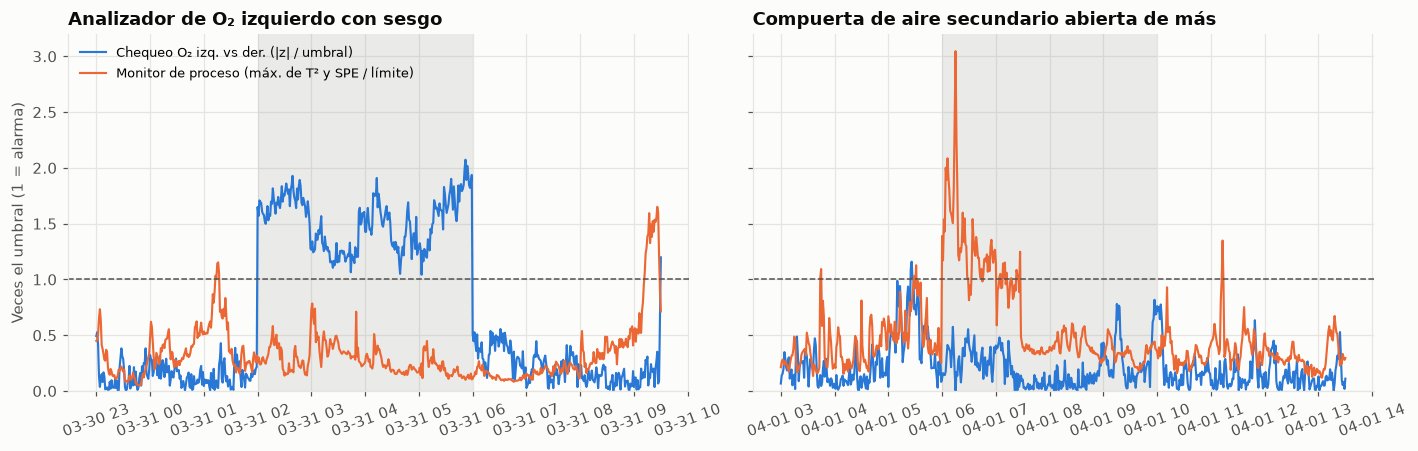

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, nombre in zip(axs, ["Analizador de O₂ izquierdo con sesgo", "Compuerta de aire secundario abierta de más"]):
    Zi, ratio, w = SERIES[nombre]
    v = slice(w.start - pd.Timedelta("3h"), w.stop + pd.Timedelta("3h"))
    ax.plot(Zi.loc[v].index, Zi.loc[v, "O2 izq. − der."].abs(), color=AZUL, lw=1.4, label="Chequeo O₂ izq. vs der. (|z| / umbral)")
    ax.plot(ratio.loc[v].index, ratio.loc[v], color=NARANJA, lw=1.4, label="Monitor de proceso (máx. de T² y SPE / límite)")
    ax.axhline(1, color=TINTA2, lw=1, ls="--"); ax.axvspan(w.start, w.stop - pd.Timedelta("30min"), color=GRIS, alpha=0.18, lw=0)
    ax.set_title(nombre, loc="left"); ax.tick_params(axis="x", rotation=20)
axs[0].set_ylabel("Veces el umbral (1 = alarma)"); axs[0].legend(frameon=False, fontsize=8.5, loc="upper left")
axs[0].set_ylim(0, None)
guardar(fig, "serie2_14_sensor_vs_proceso.png")

**Lectura:**
- **Las cuatro fallas de sensor las nombra la verificación:**
  - el O₂ izquierdo con sesgo, en 4 min, porque el derecho no coincide;
  - la presión trabada, en ~1 min, por congelada;
  - la deriva del medidor de vapor, a las ~1.7 h, cuando el error inyectado iba en ~0.9 t/h, porque el sensor
    virtual no la acompaña;
  - la deriva del termopar, a las ~4 h, cuando llevaba ~27 °C. El par izquierda-derecha es un chequeo grueso.
- **La compuerta abierta de más no dispara ningún chequeo de sensor** (los dos O₂ coinciden). La detecta el monitor de
  proceso en 4 min (aire y tiro), y luego la regla de O₂ alto, que exige 10 min: **proceso o equipo**.
- **El termopar con deriva también dispara el monitor de proceso;** entre las variables que más contribuyen están el
  lecho y los gases. Por eso importa el orden: primero la verificación de sensores. Si ella nombra un sensor, la alarma
  de proceso se atribuye a ese sensor, no a la caldera.
  - Aquí el monitor saltó ~15 min antes que el chequeo del par. Durante esos minutos el diagnóstico habría sido
    "proceso": es el costo de un chequeo de gases grueso.
- **La figura muestra el criterio:** con el O₂ dañado salta el chequeo de pares (azul) y el monitor no; con la
  compuerta abierta salta el monitor (naranja) y el chequeo no.

**Mejora siguiente.** El chequeo de gases es grueso (~27 °C). Un modelo físico de la temperatura de gases, como el del
vapor (carga, O₂, tiempo desde la última limpieza), lo afinaría.

**Cómo lo usaría el jefe de calderas:**
1. Alerta de una regla física: actuar.
2. Alerta de verificación: llamar a instrumentación y no corregir la operación por ese sensor.
3. Alerta del monitor sin alerta de verificación: revisar la operación con las variables que señala.

In [8]:
res4 = {"reglas": REG.round(2).to_dict(orient="index"), "verificacion_episodios_dia": len(EPV) / 3,
        "verificacion_por_chequeo": EPV.groupby("chequeo").size().to_dict(),
        "monitor_episodios_dia": len(EPT) / dias_mon, "monitor_episodios": EPT.astype(str).to_dict(orient="records"),
        "sensibilidad": SENS.round(3).astype({"umbral (desvíos)": float}).to_dict(orient="index"),
        "inyecciones": INY.reset_index().astype(str).to_dict(orient="records"),
        "parametros": {"persistencia_min": PERSISTE_MIN, "apagado_min": APAGA_MIN, "ventana_monitor": "24h", "q_monitor": Q_MONITOR}}
(TAB / "serie2_resumen_p4.json").write_text(json.dumps(res4, ensure_ascii=False, indent=1, default=str), encoding="utf-8")
ref_art = {"descripcion": "Serie II · verificación de sensores: centro y escala robusta de cada chequeo (referencia: 2 primeros días)",
           "centro": REFM["parametros"]["centro"].to_dict(), "escala": REFM["parametros"]["escala"].to_dict(),
           "valvula_a_agua": list(REFM["parametros"]["valvula"]),
           "virtual_dos_variables": {"a": float(REFM["virtual"].intercept_), "b": float(REFM["virtual"].coef_[0]), "c": float(REFM["virtual"].coef_[1])},
           "umbrales_z": REFM["umbrales"].to_dict(), "centro_confirmado_retorno": REFM["centro_confirmado"],
           "persistencia_min": PERSISTE_MIN, "apagado_min": APAGA_MIN}
(MOD / "serie2_verificacion.json").write_text(json.dumps(ref_art, ensure_ascii=False, indent=1, default=float), encoding="utf-8")

1641

## Evaluación gerencial (pregunta 4)

**Qué significa para el ingenio.** Con los sensores que ya tiene, una caldera puede vigilarse en tres capas:
- reglas físicas para actuar;
- verificación de sensores por redundancia;
- un monitor de proceso que aprende lo normal del último día.

La redundancia, que en la pregunta 1 parecía un detalle, es lo que permite **distinguir un sensor dañado de un
problema real**. Con un solo sensor por variable esa distinción no existe.

**Decisión recomendada.**
1. Empezar con las siete reglas físicas: entre 0.2 y 1.8 eventos por día cada una. Ajustar umbrales con los
   límites de diseño.
2. Activar la verificación de sensores sobre los pares que existen, y que cada alarma pida confirmación al operador.
3. Usar el monitor de proceso como "segunda opinión" diaria, no como alarma sonora, hasta acumular 2-3 meses de
   eventos confirmados.
4. En las calderas de bagazo: instalar redundancia donde hoy hay un solo sensor crítico, como el O₂ y la presión de
   hogar.

**Impacto estimado.**
- Evita "corregir" la combustión por un analizador de O₂ dañado (ver pregunta 5: cada punto de O₂ cuesta eficiencia).
- Detecta desvíos sostenidos del medidor de vapor desde ~1.3 t/h (~2 %); en la prueba, a las 1.7 h con ~0.9 t/h.
- Mantiene la carga de alarmas manejable: ~9 por día entre las tres capas (≈6 de reglas, medidas en 5 días y con umbrales
  calibrados en estos datos; 2 de verificación, en 3 días; 1.5 del monitor, en 4 días), todas con diagnóstico.
- El valor en dinero depende del costo de las fallas que se eviten; con 5 días sin fallas reales no se puede estimar.

**Riesgos.**
- Las fallas de prueba son sintéticas, y las fallas reales pueden ser más sutiles.
- La referencia de 2 días es corta: una operación nueva legítima, como la redistribución del aire, alarma hasta que
  se confirma, y el chequeo queda en pausa 2 h mientras se recalibra.
- Una falla común a los dos sensores de un par (por ejemplo, una toma compartida) no la detecta la verificación por
  pares.

**Nivel de certeza.**
- Alta en el criterio sensor contra equipo: 5 de 5 escenarios bien clasificados, y el criterio es físico.
- Media en las tasas de alarma: 3 días de evaluación.
- Baja en los umbrales exactos, que deben ajustarse con el jefe de calderas.

# Parte B · Pregunta 5: oportunidades de eficiencia

**Qué permiten los datos y qué no.** No hay flujo ni calidad del combustible, ni temperatura de chimenea, ni CO.
Por eso:
- La **eficiencia absoluta** no se puede medir.
- Sí se pueden medir **efectos relativos a igual carga** (qué cambia cuando sube el O₂, cómo derivan las
  temperaturas) y traducirlos a combustible con supuestos declarados.

Cada supuesto está en `SupuestosCaldera` y puede reemplazarse por el dato real.

In [9]:
S = SupuestosCaldera()
display(pd.Series(S.dict()).to_frame("supuesto"))
med = DF.median()
Q_UTIL = calor_util_gj_h(med["ZZQBCHLL"], med["PTCA_8324"], med["TE_8332A"], S)
COMB = combustible_t_h(Q_UTIL, S)
print(f"Condición típica: {med['ZZQBCHLL']:.1f} t/h de vapor a {med['PTCA_8324']:.2f} MPa y {med['TE_8332A']:.1f} °C")
print(f"Calor útil: {Q_UTIL:.1f} GJ/h | combustible con {100 * S.eficiencia:.0f} % de eficiencia: {COMB:.2f} t/h ({24 * COMB:.0f} t/día)")
W1 = tabla_proceso(DF)
W1["dias"] = (W1.index - W1.index[0]).total_seconds() / 86400; W1["hora"] = W1.index.hour
W1["t_aire_prim"] = DF["TE_8303"].resample("1min").mean(); W1["t_aire_sec"] = DF["TE_8304"].resample("1min").mean()

,supuesto
t_agua_alimentacion_c,215.00
p_agua_alimentacion_mpa,10.50
eficiencia,0.88
pci_mj_kg,23.00
precio_combustible_t,120.00
horas_ano,8000.00
perdida_por_k,0.04
dt_chimenea_amb_k,120.00
fraccion_a_chimenea,0.50
tension_tiro_kv,6.00


Condición típica: 59.9 t/h de vapor a 9.45 MPa y 537.7 °C
Calor útil: 152.8 GJ/h | combustible con 88 % de eficiencia: 7.55 t/h (181 t/día)


## B.1 Oportunidad 1: ensuciamiento de las superficies de intercambio

Si los tubos del sobrecalentador y del economizador se ensucian, absorben menos calor y los gases salen más calientes.
Se busca una **tendencia en el tiempo a igual carga, igual O₂ y misma hora del día**.

,°C por día,IC90 bajo,IC90 alto,t (HAC 2 h)
Gases a la salida del economizador superior,1.96,1.32,2.60,5.02
Aire primario precalentado,1.48,1.01,1.95,5.17
Aire secundario precalentado,1.23,0.97,1.49,7.83
Temperatura del hogar,0.25,0.02,0.49,1.75
Temperatura del vapor,0.17,-0.17,0.52,0.83


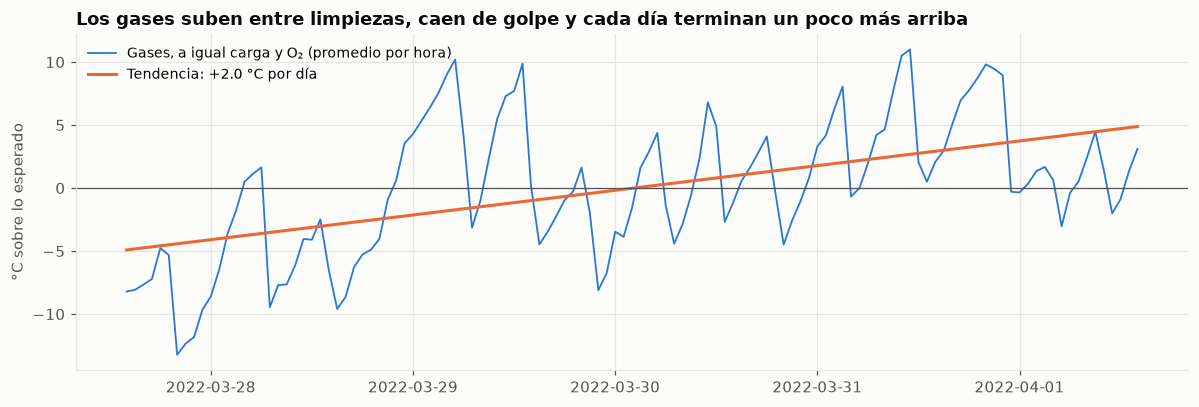

Ciclos de gases: 13 picos; cada 8.2 h (mediana); caída tras el pico: -13.9 °C en 90 min (mediana); exceso medio sobre el mínimo del ciclo: 8.2 °C


Horas desde el inicio de la última descarga del lecho hasta el pico de gases: mediana 1.6 h (al azar: 3.5 h; P(azar ≤ observado) = 0.014)
En 5 días la base de los gases subió ~10 °C. Valor de recuperar 10 °C a la salida del economizador:


,puntos_eficiencia,combustible_%,t_dia,us_ano
fracción que llega a chimenea,,,,
0.3,0.12,0.136,0.247,9871.230
0.5,0.20,0.227,0.411,16437.127
0.7,0.28,0.317,0.575,22991.124


Limpiar el doble de seguido (el exceso medio del ciclo baja a la mitad): 0.082 puntos, 0.17 t/día, US$6,743/año


In [10]:
TEND = {}
for y, nombre in [("t_gases", "Gases a la salida del economizador superior"), ("t_aire_prim", "Aire primario precalentado"),
                  ("t_aire_sec", "Aire secundario precalentado"), ("t_hogar", "Temperatura del hogar"), ("t_vapor", "Temperatura del vapor")]:
    f = smf.ols(f"{y} ~ vapor + o2 + dias + C(hora)", data=W1).fit(cov_type="HAC", cov_kwds={"maxlags": 120})
    TEND[nombre] = {"°C por día": f.params["dias"], "IC90 bajo": f.conf_int(0.10).loc["dias", 0], "IC90 alto": f.conf_int(0.10).loc["dias", 1],
                    "t (HAC 2 h)": f.tvalues["dias"]}
TEND = pd.DataFrame(TEND).T; display(TEND.round(2))
f_g = smf.ols("t_gases ~ vapor + o2", data=W1).fit()
resid_h = (W1["t_gases"] - f_g.predict(W1)).resample("1h").mean()
pend = TEND.loc["Gases a la salida del economizador superior", "°C por día"]
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(resid_h.index, resid_h, color=AZUL, lw=1.2, label="Gases, a igual carga y O₂ (promedio por hora)")
xx = np.asarray((resid_h.index - W1.index[0]).total_seconds() / 86400)
ax.plot(resid_h.index, resid_h.mean() + pend * (xx - xx.mean()), color=NARANJA, lw=2, label=f"Tendencia: {pend:+.1f} °C por día")
ax.axhline(0, color=TINTA2, lw=0.8); ax.set_ylabel("°C sobre lo esperado"); ax.legend(frameon=False, fontsize=9, loc="upper left")
ax.set_title("Los gases suben entre limpiezas, caen de golpe y cada día terminan un poco más arriba", loc="left")
guardar(fig, "serie2_15_ensuciamiento.png")

from scipy.signal import find_peaks
from fabrica_regimenes import fases_lecho
zr = (W1["t_gases"] - f_g.predict(W1)).rolling(10, center=True).mean()
pk, _ = find_peaks(zr.to_numpy(), prominence=6, distance=120); va, _ = find_peaks(-zr.to_numpy(), prominence=6, distance=120)
PIC, VAL = zr.index[pk], zr.index[va]
caidas = [zr.loc[t: t + pd.Timedelta("90min")].min() - zr.loc[t] for t in PIC]
exceso_ciclo = [(zr.loc[a:b] - zr.loc[a:b].min()).mean() for a, b in zip(VAL[:-1], VAL[1:])]
print(f"Ciclos de gases: {len(PIC)} picos; cada {np.median(np.diff(PIC).astype('timedelta64[m]').astype(float)) / 60:.1f} h (mediana); "
      f"caída tras el pico: {np.median(caidas):.1f} °C en 90 min (mediana); exceso medio sobre el mínimo del ciclo: {np.median(exceso_ciclo):.1f} °C")
_, CICL = fases_lecho(W1["lecho"]); DESC = pd.DatetimeIndex(CICL.query("fase == 'descarga'")["inicio"])
desfase = np.array([(t - DESC[DESC <= t][-1]).total_seconds() / 3600 for t in PIC if (DESC <= t).any()])
rng = np.random.default_rng(20261019)
azar = [np.median([(t - DESC[DESC <= t][-1]).total_seconds() / 3600 for t in W1.index[rng.integers(0, len(W1), len(desfase))] if (DESC <= t).any()])
        for _ in range(2000)]
print(f"Horas desde el inicio de la última descarga del lecho hasta el pico de gases: mediana {np.median(desfase):.1f} h "
      f"(al azar: {np.median(azar):.1f} h; P(azar ≤ observado) = {np.mean(np.array(azar) <= np.median(desfase)):.3f})")
subida_5d = pend * 5
filas = []
for frac in (0.3, 0.5, 0.7):
    s_ = SupuestosCaldera(fraccion_a_chimenea=frac)
    pts = puntos_por_chimenea(10 * frac, s_)
    filas.append({"fracción que llega a chimenea": frac, **ahorro(pts, Q_UTIL, s_)})
SENS1 = pd.DataFrame(filas).set_index("fracción que llega a chimenea")
print(f"En 5 días la base de los gases subió ~{subida_5d:.0f} °C. Valor de recuperar 10 °C a la salida del economizador:")
display(SENS1.round(3))
pts_freq = puntos_por_chimenea(np.median(exceso_ciclo) / 2 * S.fraccion_a_chimenea, S)
LIMP2 = ahorro(pts_freq, Q_UTIL, S)
print(f"Limpiar el doble de seguido (el exceso medio del ciclo baja a la mitad): {LIMP2['puntos_eficiencia']:.3f} puntos, "
      f"{LIMP2['t_dia']:.2f} t/día, US${LIMP2['us_ano']:,.0f}/año")

**Lectura.** La temperatura de gases tiene dos patrones a igual carga y O₂:
- **Un serrucho:** sube durante ~8 h y cae de golpe ~14 °C (13 ciclos en 5 días).
  - Es compatible con superficies que se ensucian y se limpian con sopladores de hollín, pero no hay registro de
    soplados para confirmarlo: es una **hipótesis**.
  - Los picos ocurren ~1.6 h después de iniciar una descarga del lecho, antes de lo que daría el azar (p ≈ 0.01). Hay
    dos lecturas: la limpieza va en la misma rutina del turno, o el ciclo del lecho mismo mueve la temperatura de
    gases. Con estos datos no se separan.
- **Una base que sube ~2 °C por día** (IC90 en la tabla), ~10 °C en cinco días.
- El aire precalentado también sube, mientras que la temperatura del hogar casi no cambia. Es coherente con
  superficies que absorben menos calor, sin que cambie el fuego.

**Impacto** (con los supuestos de la tabla):
- **Recuperar la deriva de la base** (10 °C) vale ~0.1-0.3 puntos de eficiencia: ~0.1-0.3 % del combustible, unos
  US$10-23 mil al año según cuánto de ese calor llegue a la chimenea. Si la causa es ensuciamiento, requiere una
  limpieza más profunda o revisar sopladores que no llegan a alguna zona.
- **Limpiar el doble de seguido** reduce a la mitad el exceso medio del serrucho, pero vale poco (ver la cifra
  impresa), porque cada ciclo ya se limpia.

**Alternativa a descartar:** la temperatura ambiente subiendo en la primavera también calienta el aire precalentado.
No explica el serrucho ni que los gases suban mientras el hogar no cambia, pero la deriva de la base no se puede
separar del clima sin el dato de temperatura ambiente.

## B.2 Oportunidad 2: exceso de aire

En la pregunta 2 apareció un eje de operación a igual carga: más O₂, más atemperación y vapor más frío. Aquí se
cuantifica qué cuesta el O₂ alto.

In [11]:
efO2 = {}
for y, nombre in [("t_gases", "Temperatura de gases (°C por punto de O₂)"), ("corriente_tiro", "Corriente del tiro inducido (A por punto de O₂)"),
                  ("t_vapor", "Temperatura del vapor (°C por punto de O₂)")]:
    f = smf.ols(f"{y} ~ vapor + o2 + dias", data=W1).fit(cov_type="HAC", cov_kwds={"maxlags": 120})
    efO2[nombre] = {"efecto": f.params["o2"], "IC90 bajo": f.conf_int(0.10).loc["o2", 0], "IC90 alto": f.conf_int(0.10).loc["o2", 1], "t": f.tvalues["o2"]}
EFO2 = pd.DataFrame(efO2).T; display(EFO2.round(3))
o2 = W1["o2"]
print("Percentiles del O₂ (1 min):", o2.quantile([0.05, 0.25, 0.5, 0.75, 0.95]).round(2).to_dict())
objetivo = round(float(o2.median()), 2)
exceso = (o2 - objetivo).clip(lower=0)
print(f"Política evaluada: cuando el O₂ supera la mediana ({objetivo} %), bajarlo a la mediana. "
      f"Ocurre el {100 * (exceso > 0).mean():.0f} % del tiempo; baja promedio {exceso.mean():.2f} puntos")
o2_nuevo = o2.where(o2 <= objetivo, objetivo)
pts_lambda = float(np.mean([puntos_por_exceso_aire(a, b, S) for a, b in zip(o2, o2_nuevo)]))
pts_gases = puntos_por_chimenea(EFO2.iloc[0]["efecto"] * exceso.mean() * S.fraccion_a_chimenea, S)
kw = kw_tiro(EFO2.iloc[1]["efecto"] * exceso.mean(), S)
OP2 = pd.DataFrame({"menos gases (λ)": ahorro(pts_lambda, Q_UTIL, S), "gases más fríos": ahorro(pts_gases, Q_UTIL, S)}).T
OP2.loc["total combustible"] = OP2.sum()
print(f"Tiro inducido: {kw:.1f} kW menos en promedio ≈ US${kw * S.horas_ano * S.precio_kwh:,.0f}/año")
display(OP2.round(3))

,efecto,IC90 bajo,IC90 alto,t
Temperatura de gases (°C por punto de O₂),4.253,3.157,5.350,6.382
Corriente del tiro inducido (A por punto de O₂),0.400,0.315,0.485,7.756
Temperatura del vapor (°C por punto de O₂),-0.929,-1.979,0.121,-1.455


Percentiles del O₂ (1 min): {0.05: 1.65, 0.25: 1.95, 0.5: 2.13, 0.75: 2.35, 0.95: 2.74}
Política evaluada: cuando el O₂ supera la mediana (2.13 %), bajarlo a la mediana. Ocurre el 50 % del tiempo; baja promedio 0.14 puntos
Tiro inducido: 0.5 kW menos en promedio ≈ US$410/año


,puntos_eficiencia,combustible_%,t_dia,us_ano
menos gases (λ),0.037,0.042,0.076,3034.230
gases más fríos,0.012,0.014,0.025,1014.985
total combustible,0.049,0.056,0.101,4049.216


**Lectura.**
- A igual carga, **cada punto de O₂ calienta los gases ~4 °C y sube ~0.4 A la corriente del tiro inducido**: más
  aire es más gas que calentar y que mover.
- La caldera ya opera con poco exceso de aire (mediana ~2.1 % de O₂).
- Bajar el O₂ a la mediana cuando la supera ahorra **menos de 0.1 punto de eficiencia**: unos US$4 mil al año, más
  ~0.5 kW en el tiro (~US$400 al año).

**Conclusión honesta:** en esta caldera el exceso de aire **no es una oportunidad grande**. Además, sin un analizador
de CO, bajar más el O₂ arriesga inquemados, que cuestan más de lo que se ahorra.

**En las calderas de bagazo esta es la palanca principal.** Por la humedad del bagazo (~50 %) suelen operar con
mucho más exceso de aire, y el mismo cálculo da cifras varias veces mayores.

## B.3 Oportunidad 3 (sin estimación confiable): control de la temperatura del vapor

- La válvula del atemperador pasó **12 h fija** (pregunta 1).
- A igual carga y O₂, cada t/h extra de agua de atemperación se asocia con ~8 °C menos en el vapor (regresión de
  abajo). En la pregunta 2, los cambios del agua preceden a los del vapor en ~5 min.
- El vapor promedia ~537.5 °C, por debajo de los ~540 °C de diseño probable, y pasa ~27 % del tiempo bajo 535 °C.

In [12]:
tv = DF["TE_8332A"]
f_at = smf.ols("t_vapor ~ vapor + agua_atemp + o2", data=W1).fit(cov_type="HAC", cov_kwds={"maxlags": 120})
print(f"A igual carga y O₂, cada t/h de agua de atemperación cambia el vapor {f_at.params['agua_atemp']:+.1f} °C "
      f"(IC90 {f_at.conf_int(0.10).loc['agua_atemp', 0]:+.1f} a {f_at.conf_int(0.10).loc['agua_atemp', 1]:+.1f})")
print(f"Vapor: media {tv.mean():.1f} °C, desvío {tv.std():.1f} °C; bajo 535 °C el {100 * (tv < 535).mean():.0f} % del tiempo; "
      f"sobre 545 °C el {100 * (tv > 545).mean():.0f} %")
from iapws import IAPWS97
dh = IAPWS97(P=float(med["PTCA_8324"]), T=540 + 273.15).h - IAPWS97(P=float(med["PTCA_8324"]), T=float(tv.mean()) + 273.15).h
print(f"Llevar la media a 540 °C agrega {dh:.1f} kJ/kg al vapor ({dh / (IAPWS97(P=float(med['PTCA_8324']), T=540 + 273.15).h - 923.4) * 100:.2f} % de la energía que recibe)")

A igual carga y O₂, cada t/h de agua de atemperación cambia el vapor -7.9 °C (IC90 -9.9 a -5.9)
Vapor: media 537.5 °C, desvío 4.3 °C; bajo 535 °C el 27 % del tiempo; sobre 545 °C el 3 %
Llevar la media a 540 °C agrega 6.2 kJ/kg al vapor (0.24 % de la energía que recibe)


**Lectura.** Controlar mejor la temperatura del vapor tiene dos efectos:
- **Atemperación en automático:** menos variación protege los tubos del sobrecalentador.
- **Una media más cerca de la de diseño** mejora el rendimiento de la turbina.

El beneficio en dinero se da en la turbina, no en la caldera, y no se puede estimar sin sus datos (presión de escape,
potencia, eficiencia). Queda como oportunidad identificada, no cuantificada.

## B.4 Qué datos harían falta para estimar con confianza

| Dato | Para qué |
|---|---|
| Flujo y poder calorífico del combustible (y humedad, en bagazo) | eficiencia absoluta: vapor producido por energía que entra |
| Temperatura de gases a la salida del precalentador (chimenea) | pérdida real por gases; hoy se supone |
| CO en gases | cuánto se puede bajar el O₂ sin inquemados |
| Registro de soplado de hollín y de descargas de ceniza | separar ensuciamiento de ciclo normal de limpieza |
| Corriente de los ventiladores primario y secundario | costo eléctrico del aire y del nivel del lecho |
| Temperatura ambiente | descartar que la deriva de temperaturas sea clima |
| Flujo y temperatura del agua de alimentación | balance de energía completo (hoy se supone 215 °C) |
| Consignas y modo de los lazos (automático o manual) | separar decisiones del operador de respuestas del control |

In [13]:
res5 = {"supuestos": S.dict(), "calor_util_gj_h": Q_UTIL, "combustible_t_h": COMB,
        "tendencias": TEND.round(3).to_dict(orient="index"), "ensuciamiento_10C": SENS1.round(4).to_dict(orient="index"),
        "efectos_o2": EFO2.round(4).to_dict(orient="index"), "o2_objetivo": objetivo, "o2_exceso_medio": float(exceso.mean()),
        "exceso_aire": OP2.round(4).to_dict(orient="index"), "kw_tiro": kw,
        "serrucho": {"picos": int(len(PIC)), "periodo_h": float(np.median(np.diff(PIC).astype("timedelta64[m]").astype(float)) / 60),
                     "caida_c": float(np.median(caidas)), "exceso_ciclo_c": float(np.median(exceso_ciclo)),
                     "desfase_descarga_h": float(np.median(desfase)), "desfase_azar_h": float(np.median(azar)),
                     "p_desfase": float(np.mean(np.array(azar) <= np.median(desfase))), "pendiente_c_dia": float(pend)},
        "gases_hora": {"t": [t.strftime("%d/%m %H:%M") for t in resid_h.index], "v": resid_h.round(2).tolist()},
        "limpiar_doble": LIMP2, "vapor": {"media": float(tv.mean()), "sd": float(tv.std()), "bajo535": float((tv < 535).mean()),
                                          "sobre545": float((tv > 545).mean()), "efecto_agua": float(f_at.params["agua_atemp"])}}
(TAB / "serie2_resumen_p5.json").write_text(json.dumps(res5, ensure_ascii=False, indent=1, default=float), encoding="utf-8")

6420

## Evaluación gerencial (pregunta 5)

**Qué significa para el ingenio.** En esta caldera la oportunidad medible más clara es la **limpieza de superficies**.
Los gases hacen un serrucho de ~8 h (compatible con ensuciamiento y soplado, sin registro que lo confirme) y su base
sube ~2 °C por día a igual operación. El **exceso de aire** ya está bajo y da poco, y la
**temperatura del vapor** tiene margen, pero su valor está en la turbina. La lección principal es de datos: sin
combustible, chimenea y CO, la eficiencia solo se puede estimar en relativo.

**Decisión recomendada.**
1. Cruzar el serrucho y la deriva de los gases con el registro de soplado de hollín. Disparar la limpieza por
   temperatura de gases, no por calendario, y revisar qué zona no se está limpiando.
2. Poner la atemperación en automático y revisar su sintonía.
3. Instalar o recuperar la medición de combustible, temperatura de chimenea y CO. En las calderas de bagazo, el
   control de exceso de aire con CO es la primera palanca.

**Impacto estimado** (con los supuestos declarados):
- Limpieza (recuperar la deriva de la base, si es ensuciamiento): ~0.1-0.3 puntos de eficiencia, unos US$10-23 mil
  al año.
- Exceso de aire: menos de 0.1 punto.
- En el ingenio, el mismo método aplicado a bagazo con O₂ alto daría cifras mayores, que habría que medir.

**Riesgos.**
- La deriva de la base puede ser en parte clima (falta el dato de ambiente).
- La fracción del calor que llega a la chimenea mueve el resultado ±40 %; los demás supuestos (pérdida por K, poder
  calorífico, eficiencia) no se variaron y lo moverían más.
- El serrucho puede deberse al ciclo del lecho y no a la limpieza: sin registro de soplados, la atribución es una
  hipótesis.
- Bajar el O₂ sin CO arriesga inquemados.

**Nivel de certeza.**
- Alta en los efectos relativos medidos: el serrucho, la deriva de ~2 °C/día y el efecto del O₂ en gases y tiro, con
  errores robustos a autocorrelación.
- Media en la causa del serrucho (ensuciamiento o ciclo del lecho).
- Baja en el valor en dinero, que depende de supuestos.